# Day16 · OCR·VLM 문서 AI 핵심 코드

2026-11-09 · Vision·멀티모달 AI 응용 4/4

문서 이미지에서 값을 꺼낼 때 **그 값의 근거(원문·위치·점수)를 함께 남기고, 근거가 없는 값은 사람이 보도록 남기는** 흐름을 1교시부터 7교시까지 한 번에 따라갑니다.

**실행 방법**
- Colab: 메뉴 `런타임 → 모두 실행`. 처음 한 번 Tesseract 설치에 1분쯤 걸립니다.
- 내 컴퓨터 Jupyter: Tesseract 엔진을 먼저 설치하고(macOS `brew install tesseract`), 커널을 `Python (dl)`로 고른 뒤 `모두 실행`. 0번 설치 셀은 Colab에서만 동작하고 여기서는 건너뜁니다.

**데이터는 따로 받지 않습니다.**
- `skimage.data.page()`: scikit-image에 들어 있는 실제 스캔 페이지. 왼쪽이 어두워 조명이 고르지 않습니다 → 1교시 이진화
- 코드로 그린 청구서: `cv2.putText`로 7줄을 그립니다. 그린 글자가 곧 정답이라 CER과 필드 정답을 바로 잴 수 있습니다

**모두 실제로 실행합니다.** OCR은 Tesseract, VLM은 작은 공개 모델 SmolVLM-256M(약 0.5GB, 4교시에서 처음 한 번 내려받음, 로그인 불필요)입니다. 6교시 TensorRT만 장비가 필요해 공식 명령을 주석으로 둡니다. Colab은 `런타임 → 런타임 유형 변경 → GPU`면 VLM이 더 빠르지만 CPU로도 됩니다.

## 0. 설치 (Colab에서만)
Tesseract OCR 엔진과 Python 연결 라이브러리를 설치합니다. OpenCV·scikit-image·pandas·transformers는 Colab에 이미 있습니다. 내 컴퓨터에서는 아무것도 하지 않습니다.

In [8]:
import sys

if "google.colab" in sys.modules:
    !apt-get -qq install -y tesseract-ocr > /dev/null
    !pip -q install pytesseract jiwer

## import

In [9]:
import json
import re

import cv2
import jiwer
import numpy as np
import pytesseract
from skimage import data
from transformers import pipeline

## 이미지 보기 준비
Colab에는 `cv2_imshow`가 있습니다. 내 컴퓨터 Jupyter에는 없어서 같은 이름의 함수를 만듭니다. 이 셀은 화면에 보여 주는 용도라 핵심 코드에는 없습니다.

In [10]:
try:
    from google.colab.patches import cv2_imshow   # Colab
except ImportError:
    from IPython.display import Image, display

    def cv2_imshow(img):                          # 내 컴퓨터 Jupyter
        ok, png = cv2.imencode(ext=".png", img=img)
        display(Image(data=png.tobytes()))

## 준비 · 데이터
내장 스캔 페이지를 불러오고, 청구서를 그린 뒤 **일부러 비스듬히 찍은 사진**처럼 바꿉니다. 1교시에서 이 사진을 다시 정면으로 되돌립니다.

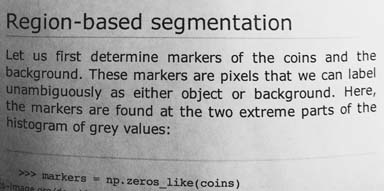

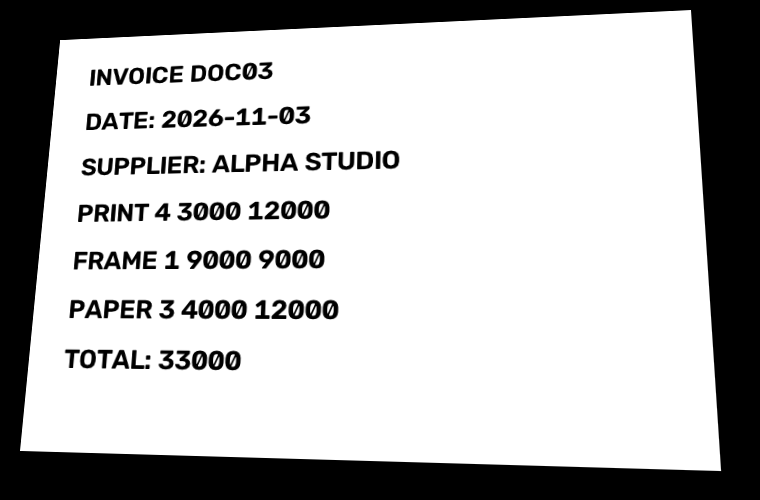

In [11]:
page = data.page()                   # scikit-image 내장 스캔 페이지 (왼쪽이 어둡다)

lines = [
    "INVOICE DOC03",
    "DATE: 2026-11-03",
    "SUPPLIER: ALPHA STUDIO",
    "PRINT 4 3000 12000",
    "FRAME 1 9000 9000",
    "PAPER 3 4000 12000",
    "TOTAL: 33000",
]                                    # 청구서에 쓸 글자 = 정답
invoice = np.full(shape=(480, 700, 3), fill_value=255, dtype=np.uint8)  # 흰 종이
for i, line in enumerate(lines):
    y = 60 + 55 * i                  # 줄마다 55픽셀씩 아래로
    cv2.putText(
        img=invoice,
        text=line,
        org=(40, y),                 # 글자를 쓰기 시작할 위치 (x, y)
        fontFace=cv2.FONT_HERSHEY_SIMPLEX,
        fontScale=1,
        color=(0, 0, 0),             # 검정 (B, G, R)
        thickness=2,
    )

# 네 모서리 순서: 왼쪽 위 → 오른쪽 위 → 오른쪽 아래 → 왼쪽 아래
corners = np.float32([[60, 40], [690, 10], [720, 470], [20, 450]])  # 사진 속 문서
front = np.float32([[0, 0], [699, 0], [699, 479], [0, 479]])        # 정면 문서
tilt = cv2.getPerspectiveTransform(src=front, dst=corners)   # 정면 → 비스듬
photo = cv2.warpPerspective(src=invoice, M=tilt, dsize=(760, 500))  # 비스듬한 사진

cv2_imshow(page)      # 왼쪽이 어두운 스캔 페이지
cv2_imshow(photo)     # 비스듬한 청구서 사진

## 1교시 · 전처리
- **이진화:** 글자(검정)와 배경(흰색)을 나눕니다. Adaptive Threshold는 주변 31×31 블록마다 기준을 따로 잡아서, 조명이 고르지 않은 페이지에서도 글자를 살립니다.
- **원근 보정:** 사진 속 문서의 네 모서리(`corners`)를 정면 네 모서리(`front`)로 옮깁니다. 두 목록의 **순서가 같아야** 합니다.

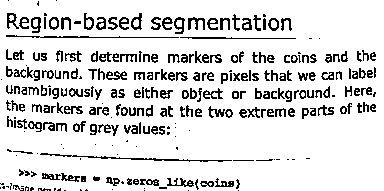

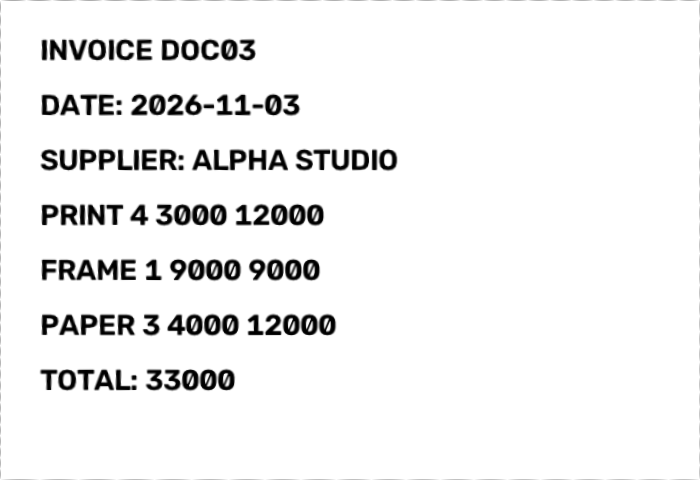

In [12]:
binary = cv2.adaptiveThreshold(
    src=page,
    maxValue=255,                    # 기준보다 밝은 픽셀 → 흰색(255)
    adaptiveMethod=cv2.ADAPTIVE_THRESH_GAUSSIAN_C,  # 주변의 가중 평균으로 기준
    thresholdType=cv2.THRESH_BINARY,
    blockSize=31,                    # 주변 31×31 칸을 보고 기준을 정한다
    C=11,                            # 그 평균에서 11을 뺀 값이 기준
)
M = cv2.getPerspectiveTransform(src=corners, dst=front)     # 사진 → 정면
warped = cv2.warpPerspective(src=photo, M=M, dsize=(700, 480))  # (너비, 높이)
cv2.imwrite(filename="invoice.png", img=warped)  # 원본 photo는 그대로 둔다

cv2_imshow(binary)
cv2_imshow(warped)

## 2교시 · OCR
`image_to_data`는 단어마다 **Text·Box(left, top, width, height)·Confidence**를 줍니다. confidence는 정답 확률이 아니라 **검토 순서**입니다. 낮은 점수는 지우지 않고 검토 목록으로 남깁니다.

CER = (치환 + 삭제 + 삽입) ÷ 정답 글자 수

In [13]:
text = pytesseract.image_to_string(image=warped, config="--psm 6")
words = pytesseract.image_to_data(
    image=warped,
    config="--psm 6",                # 페이지 모양 가정: 글 블록 하나
    output_type=pytesseract.Output.DATAFRAME,  # 결과를 표(DataFrame)로
)
words = words[words.conf >= 0]          # 단어가 있는 행만 남긴다
review = words[words.conf < 50]         # 점수가 낮은 단어 → 지우지 않고 검토 목록
truth = " ".join(lines)                 # 정답 글자
read = " ".join(text.split())           # OCR 글자 (줄바꿈·공백을 한 칸으로)
score = jiwer.cer(reference=truth, hypothesis=read)  # 글자 오류율 CER

print(text)
print("CER:", round(score, 4))
print("검토 목록(conf < 50):", len(review), "개")
words[["text", "conf", "left", "top", "width", "height"]]

INVOICE DOCO3

DATE: 2026-11-03
SUPPLIER: ALPHA STUDIO
PRINT 4 3000 12000
FRAME 1 9000 9000
PAPER 3 4000 12000
TOTAL: 33000

CER: 0.0082
검토 목록(conf < 50): 0 개


,text,conf,left,top,width,height
4,INVOICE,92.813255,42,40,110,20
5,DOCO3,65.634384,162,39,93,21
8,DATE:,96.366982,42,95,80,20
9,2026-11-03,96.488228,131,94,168,21
11,SUPPLIER:,96.406212,41,150,143,20
12,ALPHA,96.636192,193,150,95,20
13,STUDIO,96.267052,296,149,101,21
15,PRINT,96.249847,42,205,81,20
16,4,94.521324,130,205,18,20
17,3000,95.767410,156,204,71,21


## 3교시 · 구조화
라벨(`TOTAL:`) 줄에서 값을 찾고, **원문(raw)·정규화값(value)·점수·위치**를 함께 남깁니다. 품목 금액의 합이 합계와 다르면 검토 이유를 기록합니다.

In [14]:
match = re.search(
    pattern=r"^TOTAL: (\d+)$",       # "TOTAL: " 뒤의 숫자
    string=text,
    flags=re.MULTILINE,              # ^와 $를 줄마다 적용
)
raw = match.group(1)                    # "33000" : OCR이 읽은 원문
row = words[words.text == raw].iloc[0]  # 그 숫자가 적힌 단어 (첫 번째 행)
total = {
    "raw": raw,
    "value": int(raw),                  # 33000 : 숫자로 바꾼 값
    "conf": float(row.conf),
    "box": [int(row.left), int(row.top), int(row.width), int(row.height)],
}
amounts = re.findall(
    pattern=r"^[A-Z]+ \d+ \d+ (\d+)$",  # 품목 줄의 마지막 숫자 = 금액
    string=text,
    flags=re.MULTILINE,
)
reasons = []
if sum(int(a) for a in amounts) != total["value"]:  # 품목 합 ≠ 합계면 검토
    reasons.append("total_mismatch")

print(total)
print("검토 이유:", reasons)

{'raw': '33000', 'value': 33000, 'conf': 95.499481, 'box': [146, 369, 89, 21]}
검토 이유: []


## 4교시 · VLM 질문
이미지와 질문을 **하나의 메시지**에 넣어 VLM에 묻습니다. 호출 코드는 강의 PDF p.54, Hugging Face 공식 문서와 같습니다. `do_sample=False`면 같은 입력에 같은 답이 나옵니다. (수업 실습의 기본 경로는 강사가 써 둔 제공 응답입니다.)

In [15]:
pipe = pipeline(
    task="image-text-to-text",
    model="HuggingFaceTB/SmolVLM-256M-Instruct",
)
messages = [
    {"role": "user", "content": [
        {"type": "image", "path": "invoice.png"},
        {"type": "text", "text": "What is the total amount?"},
    ]},
]
out = pipe(
    text=messages,
    max_new_tokens=128,              # 답의 최대 길이 (토큰 수)
    do_sample=False,                 # 같은 입력 → 같은 답
    return_full_text=False,          # 질문은 빼고 답만 받는다
)
answer = out[0]["generated_text"].strip()  # VLM의 답 (문자열)

print(answer)

Device set to use mps:0


33000


## 5교시 · 결합과 평가
VLM의 답이 OCR이 읽은 원문과 같을 때만 채택합니다. 다르면 `None`(보류)으로 두고 사람이 확인합니다. **보류는 정답으로 세지 않습니다.**

In [16]:
if answer == total["raw"]:
    final = total["value"]              # 두 결과가 같다 → 채택
else:
    final = None                        # 다르다 → 보류, 사람이 확인

print("VLM 답:", answer, "| OCR 원문:", total["raw"], "| 최종 값:", final)

VLM 답: 33000 | OCR 원문: 33000 | 최종 값: 33000


## 6교시 · 배포 설계
장비 없이 순서와 조건만 기록합니다. Engine Build는 실제로 돌릴 장치(Jetson·GPU)에서 합니다.

In [17]:
# torch.onnx.export(model=model, args=(x,), f="model.onnx")  # PyTorch → ONNX
# trtexec --onnx=model.onnx --saveEngine=model.engine   # 대상 장치에서 Build

## 7교시 · 통합 기록
한 문서의 처리 결과를 하나의 JSON으로 남깁니다. 8교시에는 이 노트북을 다시 실행해 같은 결과가 나오는지 대조합니다.

In [18]:
record = {
    "document_id": "doc03",
    "cer": score,
    "total_amount": total,
    "review_reasons": reasons,
    "vlm_answer": answer,
    "final": final,
}
with open(file="doc03.json", mode="w", encoding="utf-8") as f:
    json.dump(obj=record, fp=f, ensure_ascii=False, indent=2)

print(open("doc03.json", encoding="utf-8").read())

{
  "document_id": "doc03",
  "cer": 0.00819672131147541,
  "total_amount": {
    "raw": "33000",
    "value": 33000,
    "conf": 95.499481,
    "box": [
      146,
      369,
      89,
      21
    ]
  },
  "review_reasons": [],
  "vlm_answer": "33000",
  "final": 33000
}


---
## 직접 바꿔 보기
한 번에 **한 곳만** 바꾸고 CER이나 필드가 어떻게 달라지는지 봅니다.

### ① 이진화: Otsu vs Adaptive
Otsu는 페이지 전체에 기준 하나를 씁니다. 스캔 페이지의 정답 글자는 손으로 옮겨 적었습니다.

Gray 그대로     : 0.324
Otsu (기준 157.0 ): 0.361
Adaptive 31, 11 : 0.057


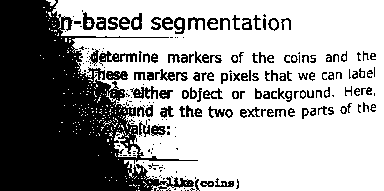

In [19]:
page_lines = [
    "Region-based segmentation",
    "Let us first determine markers of the coins and the",
    "background. These markers are pixels that we can label",
    "unambiguously as either object or background. Here,",
    "the markers are found at the two extreme parts of the",
    "histogram of grey values:",
    ">>> markers = np.zeros_like(coins)",
]                                            # 스캔 페이지의 글자 = 정답
PAGE_TEXT = "\n".join(page_lines)

def page_cer(image):
    page_read = pytesseract.image_to_string(image=image, config="--psm 6")
    page_truth = " ".join(PAGE_TEXT.split())     # 줄바꿈·공백을 한 칸으로
    page_score = jiwer.cer(reference=page_truth, hypothesis=" ".join(page_read.split()))
    return round(page_score, 3)

t, otsu = cv2.threshold(
    src=page,
    thresh=0,                        # Otsu가 기준을 직접 고르므로 0
    maxval=255,
    type=cv2.THRESH_BINARY + cv2.THRESH_OTSU,
)
print("Gray 그대로     :", page_cer(page))
print("Otsu (기준", t, "):", page_cer(otsu))
print("Adaptive 31, 11 :", page_cer(binary))
cv2_imshow(otsu)

### ② Adaptive의 blockSize와 C
값을 바꿔 가며 CER을 봅니다. blockSize는 3 이상 **홀수**여야 합니다(짝수를 넣으면 오류).

In [20]:
for block_size, C in [(31, 11), (3, 11), (101, 11), (31, 0), (31, 30), (31, 60)]:
    b = cv2.adaptiveThreshold(
        src=page,
        maxValue=255,
        adaptiveMethod=cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        thresholdType=cv2.THRESH_BINARY,
        blockSize=block_size,
        C=C,
    )
    print("blockSize", block_size, "C", C, "→ CER", page_cer(b))

blockSize 31 C 11 → CER 0.057
blockSize 3 C 11 → CER 0.137
blockSize 101 C 11 → CER 0.084
blockSize 31 C 0 → CER 0.388
blockSize 31 C 30 → CER 0.02
blockSize 31 C 60 → CER 0.221


### ③ 모서리 순서를 바꾸면
같은 네 점인데 **시작점을 오른쪽 위로** 잡았습니다. 문서가 90도 돌아가 찌그러집니다. 잘못 끼어든 글자 때문에 CER이 1을 넘을 수 있습니다.

CER: 1.254


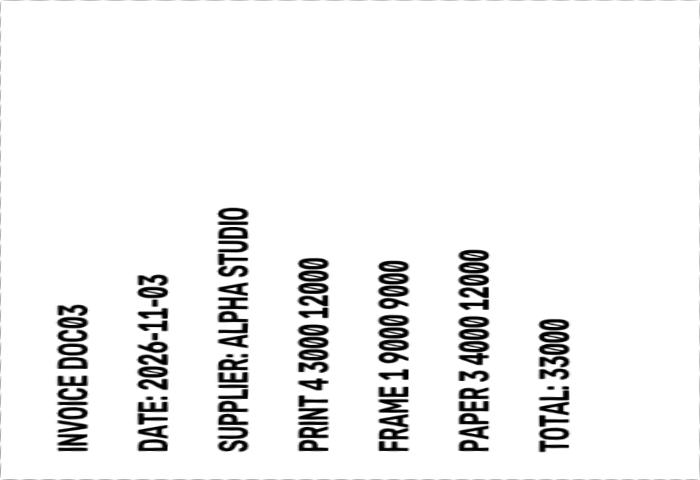

In [21]:
wrong = np.float32([[690, 10], [720, 470], [20, 450], [60, 40]])   # 시작점이 오른쪽 위
M_wrong = cv2.getPerspectiveTransform(src=wrong, dst=front)
bad = cv2.warpPerspective(src=photo, M=M_wrong, dsize=(700, 480))
bad_text = pytesseract.image_to_string(image=bad, config="--psm 6")
bad_score = jiwer.cer(reference=truth, hypothesis=" ".join(bad_text.split()))
print("CER:", round(bad_score, 3))
cv2_imshow(bad)

### ④ PSM: 페이지 구조 가정
PSM 6은 글 블록, 7은 **한 줄**, 8은 **한 단어**로 가정합니다. 전체 페이지를 한 줄로 가정하면 어떻게 될까요?

In [22]:
for psm in [6, 7, 8]:
    psm_text = pytesseract.image_to_string(image=warped, config=f"--psm {psm}")
    print("PSM", psm, "→", repr(psm_text.strip()[:60]))

PSM 6 → 'INVOICE DOCO3\n\nDATE: 2026-11-03\nSUPPLIER: ALPHA STUDIO\nPRINT'
PSM 7 → ''
PSM 8 → 'a'


### ⑤ confidence 분포
점수가 낮은 단어부터 봅니다. 틀린 단어(`DOCO3`, 숫자 0을 글자 O로 읽음)는 몇 점일까요? 기준 50이면 걸릴까요?

In [23]:
words.sort_values("conf")[["text", "conf"]].head(5)

,text,conf
5,DOCO3,65.634384
4,INVOICE,92.813255
16,4,94.521324
30,TOTAL:,95.103539
22,9000,95.112854


---
## VLM에 다른 질문 던져 보기
4교시에서 불러온 모델(`pipe`)에 질문만 바꿔 묻습니다. 작은 모델이라 답이 엉성할 수 있습니다. **그래서 근거 대조가 필요하다**는 것을 직접 확인하는 칸입니다.

In [24]:
def ask(question, max_new_tokens=128):
    messages = [
        {"role": "user", "content": [
            {"type": "image", "path": "invoice.png"},
            {"type": "text", "text": question},
        ]},
    ]
    out = pipe(
        text=messages,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        return_full_text=False,
    )
    return out[0]["generated_text"].strip()

print("공급자 →", ask("What is the supplier name?"))
print("날짜   →", ask("What is the issue date?"))

공급자 → ALPHA STUDIO
날짜   → 2026-11-03


### 문서에 없는 값을 물으면?
청구서에는 세금·할인·전화번호가 없습니다. "모르면 null이라고 답해"를 붙이면 지켜질까요?

In [25]:
print("세금        →", ask("What is the tax amount?"))
print("할인액      →", ask("What is the discount amount?"))
print("전화번호    →", ask("What is the supplier phone number?"))
print("세금(null)  →", ask("What is the tax amount? If it is not written, answer null."))

세금        → 0.
할인액      → 33000
전화번호    → ALPHA STUDIO
세금(null)  → 0.


### 답이 잘리면? 형식을 지킬까?
`max_new_tokens`를 3으로 줄여 보고, JSON으로 답하라고 해 봅니다. `json.loads`가 성공하는 것과 요청한 key(answer·evidence)가 온 것은 다릅니다.

In [26]:
print("토큰 3개 →", ask("What is the total amount?", max_new_tokens=3))

reply = ask("Return JSON with keys answer and evidence. What is the total?")
print("JSON 요청 →", reply)
try:
    parsed = json.loads(s=reply)          # "33000"만 오면 숫자로 읽혀서 성공한다
except json.JSONDecodeError:
    parsed = None
print("answer·evidence key가 있나:", isinstance(parsed, dict) and "evidence" in parsed)

토큰 3개 → 33
JSON 요청 → 33000
answer·evidence key가 있나: False
